# Solar Radiation Spatial Distribution

Pick an hour of solar radiation and see the spatial distribution.

## Set up


In [1]:
# weight path

path_weight_CaSR = "/home/jqiu/analysis-junqi/Analysis_Atmospheric_Forcing/Data_weights/weights-CaSR_202108.nc"

path_weight_HRDPS25 = '/ocean/jqiu/MOAD/grid/weights-continental2.5-hrdps_202108_23feb23onward.nc'

In [2]:
# forcing field path

path_HRDPS25 = "/results/forcing/atmospheric/continental2.5/nemo_forcing/hrdps_y2023m03d01.nc"

path_CaSR = "/ocean/jqiu/forcings/CaSR/CaSR_y2023m03d01.nc"

## Solar in NEMO grids

In [3]:
import numpy as np
import xarray as xr


def interpolate_solar(forcing_path, weight_path):

    # Extract solar radiation at the first time step
    with xr.open_dataset(forcing_path) as ds:
        solar = ds["solar"][0].transpose("y", "x").values

    solar_flat = solar.ravel()

    # Interpolate onto the NEMO grid
    with xr.open_dataset(weight_path) as weights:

        solar_nemo = np.zeros_like(
            weights["wgt01"].values, dtype=float
        )

        for i in range(1, 5):
            src = weights[f"src{i:02d}"].values.astype(int) - 1
            wgt = weights[f"wgt{i:02d}"].values

            solar_nemo += solar_flat[src] * wgt

    return solar_nemo


# Solar radiation on the NEMO grid
solar_CaSR = interpolate_solar(path_CaSR, path_weight_CaSR)

solar_HRDPS25 = interpolate_solar(path_HRDPS25, path_weight_HRDPS25)

print("CaSR:", solar_CaSR.shape)
print("HRDPS25:", solar_HRDPS25.shape)

CaSR: (898, 398)
HRDPS25: (898, 398)


In [4]:
solar_diff = solar_CaSR - solar_HRDPS25

## Visualize

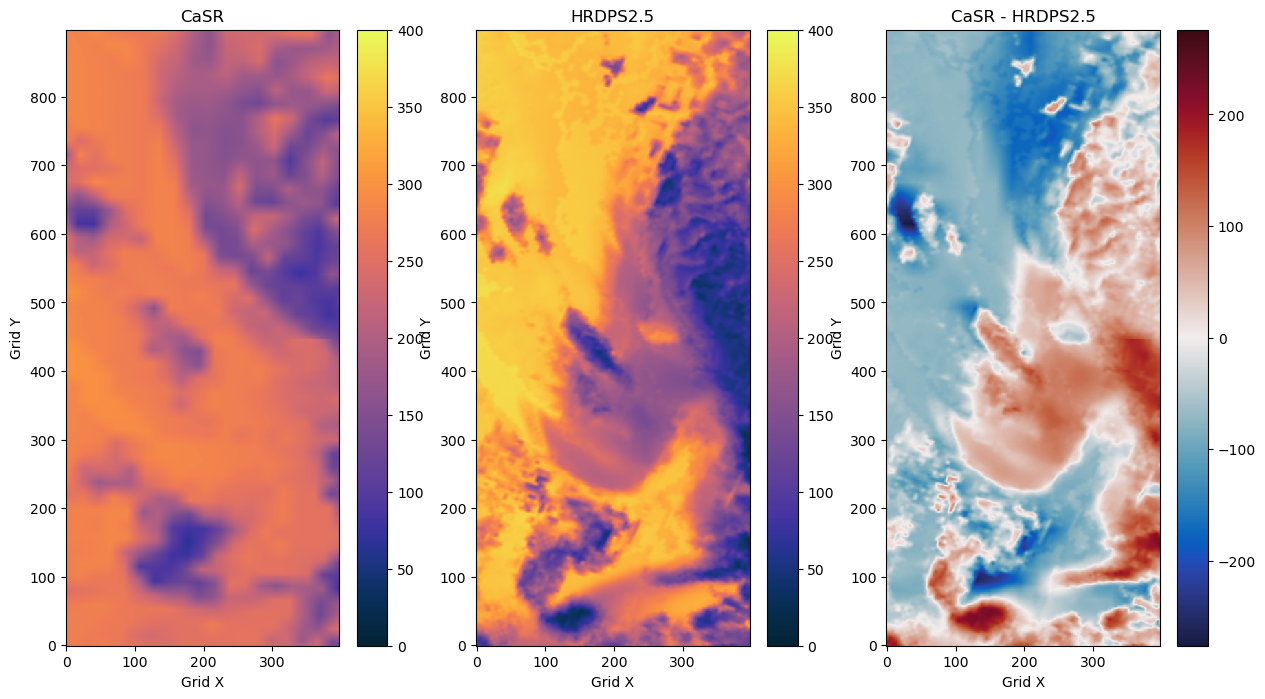

In [9]:
import cmocean.cm as cm
import matplotlib.pyplot as plt
import xarray as xr

fig, axs = plt.subplots(1, 3, figsize=(15, 8))

vmin=0
vmax=400

xr.DataArray(solar_CaSR).plot(ax=axs[0], cmap=cm.thermal,vmin=vmin, vmax=vmax)
axs[0].set_title('CaSR')

xr.DataArray(solar_HRDPS25).plot(ax=axs[1], cmap=cm.thermal,vmin=vmin, vmax=vmax)
axs[1].set_title('HRDPS2.5')

xr.DataArray(solar_diff).plot(ax=axs[2], cmap=cm.balance, center=0)
axs[2].set_title('CaSR - HRDPS2.5')

for ax in axs:
    ax.set_xlabel('Grid X')
    ax.set_ylabel('Grid Y')




